# Express Links · Week 3, step 10: the seven graph versions (Al Zahraa)

**Step 10.** For every dataset, build the graph versions that step 12 trains on. Each version adds the **same number of links K** to the same road graph and changes only **where** they go, so if express links forecast better we can say which ingredient made the difference.

No GPU needed: a CPU runtime, a few minutes. It processes every dataset whose ρ file (step 6) and road graph exist and skips the others with a message.

| Version | File | Where the K links go | What it tests |
|---|---|---|---|
| `original` | the road graph (not written here) | none | the baseline |
| `random` | `random_K{K}.pkl` | K pairs drawn at random | is any extra link enough? |
| `map_only` | `map_only_K{K}.pkl` | the pairs that save the most total R, **ignoring ρ** | does placing links at bottlenecks help on its own? |
| `corr_only` | `corr_only_K{K}.pkl` | the K pairs with the highest ρ, **ignoring R** | does linking related roads help on its own? |
| `same_side` | `same_side_K{K}.pkl` | strong-ρ pairs **inside one district**, matched one by one to the ρ of the express links | **the key control:** same strength of delayed match, but never across a bottleneck |
| `express` | `express_K{K}.pkl` (step 7) | ρ × total R saved | our method |
| `virtual_node` | `virtual_node_K25.pkl` | one extra node linked to every road | the existing traffic fix (global hub) |

`express` is rebuilt here with step 7's rule and **checked against step 7's file**, so every version comes from the same code and the same inputs.

**Reads (already in Drive)**

| What | Where | From |
|---|---|---|
| road graph | `data/raw/adj_mx.pkl`, `adj_mx_bay.pkl`, `data/raw/toy/<dataset>_adj_mx.pkl`, `data/raw/sharjah/SHARJAH_adj_mx.pkl` | steps 2, 8, 11 |
| ρ, delays, leader flags | `data/processed/<dataset>/rho/rho.npz` | step 6 |
| districts | `data/processed/<dataset>/bottleneck/regions.npz` or `<dataset>_regions.json` | steps 5, 8, 11 |
| express links | `data/graphs/<dataset>/express_K{K}_links.csv` | step 7 |
| toy map (figure only) | `data/raw/toy/TOY-C1_locations.csv` | step 8 |

**Writes:** `data/graphs/<dataset>/<version>_K{K}.pkl` for K = 5, 10, 25, 50 (the K sweep of step 15 uses random, corr_only and express), `virtual_node_K25.pkl`, a `<version>_K{K}_links.csv` next to each, and `versions_summary.csv` (the table of section 7). Step 12 finds these files under exactly these names.

**Choices made here (state them in the report):**

1. **Same rules for every version:** one-way links with the median weight of the existing links (as in step 7); never a pair that is already linked; only sensors in the graph's main connected part; step 5's **dead ends are excluded** from every version (as in step 7), so no version can spend links on them.
2. **random:** unordered pairs drawn uniformly from all allowed pairs, each with a random direction. One fixed draw (`SEED = 0`), so all three training seeds see the same random graph. The draw is nested: the K = 5 links are the first 5 of the K = 50 links.
3. **map_only:** the express loop with ρ removed: greedily add the link that saves the most total R, update, repeat. ρ is not used, so the direction is random.
4. **corr_only:** the K strongest true-leader pairs (ρ ≥ 0.2), in the leader→follower direction. R is not used.
5. **same_side:** for each express link, in order, the unused strong true-leader pair (ρ ≥ 0.2) **with both ends in one district** whose ρ is closest. So same_side and express have the same ρ link by link, and differ only in crossing the bottleneck. For PEMS-BAY (one district: no bottleneck found in step 5) every link is "same side", so this control means nothing there; say so in the report.
6. **virtual_node:** one extra node, `VIRTUAL`, linked both ways to every sensor with the median weight. It has no readings; step 12 pads its data column with zeros, which the masked loss ignores. It does not depend on K.

## 1. Connect Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob

# Find the shared 'Coding' folder. It works whether the folder is in your own Drive or is
# your teammate's folder added to My Drive as a shortcut (Organize -> Add shortcut -> My Drive).
FOLDER = os.path.join('AdvML_F26_Project_&_Survey_Paper', 'Project', 'Coding')
ROOTS = ['/content/drive/MyDrive', '/content/drive/.shortcut-targets-by-id', '/content/drive/Shareddrives']
hits = []
for root in ROOTS:
    for depth in range(4):                      # the folder may sit up to 3 levels down
        hits += glob.glob(os.path.join(root, *(['*'] * depth), FOLDER))
hits = sorted(set(h for h in hits if os.path.isdir(os.path.join(h, 'data'))), key=len)
assert hits, ("Couldn't find the 'Coding' folder. In Google Drive open 'Shared with me', right-click "
              "'AdvML_F26_Project_&_Survey_Paper' -> Organize -> Add shortcut -> My Drive, then rerun this cell.")
PROJECT_DIR = hits[0]
print('PROJECT_DIR =', PROJECT_DIR)

# Results are written into the shared folder, so you need Editor access to it
try:
    probe = os.path.join(PROJECT_DIR, '.write_test')
    open(probe, 'w').close(); os.remove(probe)
    print('OK  you can write to this folder')
except OSError:
    raise PermissionError('You can read this folder but not write to it. Ask the owner to share it with you as Editor.')

Mounted at /content/drive
PROJECT_DIR = /content/drive/MyDrive/AdvML_F26_Project_&_Survey_Paper/Project/Coding
OK  you can write to this folder


## 2. Settings and inputs

In [2]:
import os, json, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp, scipy.sparse.csgraph as cg

RAW_DIR   = os.path.join(PROJECT_DIR, 'data', 'raw')
PROC_DIR  = os.path.join(PROJECT_DIR, 'data', 'processed')
GRAPH_DIR = os.path.join(PROJECT_DIR, 'data', 'graphs')
FIG_DIR   = os.path.join(PROJECT_DIR, 'figures')
for d in [GRAPH_DIR, FIG_DIR]: os.makedirs(d, exist_ok=True)

DATASETS     = ['TOY-C1', 'METR-LA', 'PEMS-BAY', 'SHARJAH']
K_LIST       = [5, 10, 25, 50]
K_MAIN       = 25            # the K of the seven-version comparison (step 12)
RHO_MIN      = 0.2           # same as step 7
DEAD_END_MAX = 3             # same as step 7 / step 5
SEED         = 0             # the one random draw for the random version
VERSIONS     = ['random', 'map_only', 'corr_only', 'same_side', 'express', 'virtual_node']

def first_existing(paths):
    return next((p for p in paths if os.path.exists(p)), None)

def find_inputs(name):
    special = {'METR-LA': 'adj_mx.pkl', 'PEMS-BAY': 'adj_mx_bay.pkl'}
    graph = first_existing(([os.path.join(RAW_DIR, special[name])] if name in special else []) +
                           [os.path.join(RAW_DIR, 'toy', f'{name}_adj_mx.pkl'),
                            os.path.join(RAW_DIR, 'sharjah', f'{name}_adj_mx.pkl')])
    regions = first_existing([os.path.join(PROC_DIR, name, 'bottleneck', 'regions.npz'),
                              os.path.join(RAW_DIR, 'toy', f'{name}_regions.json'),
                              os.path.join(RAW_DIR, 'sharjah', f'{name}_regions.json')])
    return dict(graph=graph, regions=regions, rho=first_existing([os.path.join(PROC_DIR, name, 'rho', 'rho.npz')]))

INPUTS, READY = {}, []
for name in DATASETS:
    f = INPUTS[name] = find_inputs(name)
    missing = [k for k in ['graph', 'rho'] if f[k] is None]
    if missing:
        print(f'SKIP  {name}: no {" or ".join(missing)} file yet (rho comes from step 6-7); rerun once it is in Drive')
        continue
    READY.append(name)
    rel = lambda p: os.path.relpath(p, PROJECT_DIR) if p else 'not found'
    print(f'OK    {name}: graph {rel(f["graph"])} | rho {rel(f["rho"])} | districts {rel(f["regions"])}')
assert READY, 'No dataset has both a road graph and rho.npz yet: run step 6-7 first.'

OK    TOY-C1: graph data/raw/toy/TOY-C1_adj_mx.pkl | rho data/processed/TOY-C1/rho/rho.npz | districts data/raw/toy/TOY-C1_regions.json
OK    METR-LA: graph data/raw/adj_mx.pkl | rho data/processed/METR-LA/rho/rho.npz | districts data/processed/METR-LA/bottleneck/regions.npz
OK    PEMS-BAY: graph data/raw/adj_mx_bay.pkl | rho data/processed/PEMS-BAY/rho/rho.npz | districts data/processed/PEMS-BAY/bottleneck/regions.npz
OK    SHARJAH: graph data/raw/sharjah/SHARJAH_adj_mx.pkl | rho data/processed/SHARJAH/rho/rho.npz | districts data/raw/sharjah/SHARJAH_regions.json


## 3. Shared functions

The graph maths is the same as step 7: R from the Laplacian pseudoinverse L⁺ (graph treated as two-way), the exact one-link update of L⁺, and **total R saved** S(u, v) = drop in the sum of R over all pairs if the link u–v is added. `greedy_links` is step 7's loop with the scoring left open: `express` scores ρ × S, `map_only` scores S alone.

In [3]:
def load_graph(name):
    with open(INPUTS[name]['graph'], 'rb') as f:
        sensor_ids, id_to_ind, adj = pickle.load(f, encoding='latin1')
    return sensor_ids, id_to_ind, np.asarray(adj, dtype=np.float32)

def undirected(adj):
    W = np.maximum(adj, adj.T).astype(float); np.fill_diagonal(W, 0); return W

def main_component(W):
    _, lab = cg.connected_components(sp.csr_matrix(W > 0), directed=False)
    return lab == np.bincount(lab).argmax()

def laplacian_pinv(W):
    n = len(W); L = np.diag(W.sum(1)) - W; J = np.ones((n, n)) / n
    return np.linalg.inv(L + J) - J

def R_from_pinv(P):
    d = np.diag(P); R = d[:, None] + d[None, :] - 2 * P
    np.fill_diagonal(R, 0); return np.maximum(R, 0)

def add_link_update(P, u, v, w=1.0):
    b = P[:, u] - P[:, v]
    return P - w * np.outer(b, b) / (1 + w * (b[u] - b[v]))

def total_R_saved(P, w):
    n = len(P); P2 = P @ P; d2 = np.diag(P2)
    Q = d2[:, None] + d2[None, :] - 2 * P2
    S = n * w * Q / (1 + w * R_from_pinv(P)); np.fill_diagonal(S, 0)
    return np.maximum(S, 0)

def total_R(P):
    return len(P) * np.trace(P)

def dead_ends(W, R, in_main, max_size=DEAD_END_MAX):
    '''Step 5 / step 7 dead ends: sensors cut off from the main part by one link, at most max_size of them.'''
    out = np.zeros(len(W), bool)
    iu, iv = np.nonzero(np.triu(W > 0, 1))
    for a, b in zip(iu, iv):
        if in_main[a] and in_main[b] and W[a, b] * R[a, b] >= 0.999:
            W2 = W.copy(); W2[a, b] = W2[b, a] = 0
            _, lab = cg.connected_components(sp.csr_matrix(W2[np.ix_(in_main, in_main)] > 0), directed=False)
            small = np.flatnonzero(in_main)[lab == np.argmin(np.bincount(lab))]
            if len(small) <= max_size:
                out[small] = True
    return out

def load_districts(name, ids):
    p = INPUTS[name]['regions']
    if p is None:
        return None
    if p.endswith('.npz'):
        z = np.load(p, allow_pickle=True)
        d = dict(zip([str(s) for s in z['sensor_ids']], z['district'].tolist()))
    else:
        with open(p) as f:
            d = {str(k): v for k, v in json.load(f)['district'].items()}
    return np.array([str(d.get(s, -1)) for s in ids])

def greedy_links(score_by, rho, candidates, Lplus, in_main, K, weight, rng=None):
    '''Step 7's loop. score_by: 'express' (rho x total R saved) or 'map_only' (total R saved).
    candidates: (N, N) bool, ordered pairs u->v allowed. Returns a list of (u, v), in the order added.
    For map_only, an unordered pair is scored once and given a random direction.'''
    N = len(candidates)
    main = np.where(in_main)[0]; pos = -np.ones(N, int); pos[main] = np.arange(len(main))
    cand = candidates.copy(); P = Lplus.copy(); out = []
    if score_by == 'map_only':
        cand = np.triu(cand | cand.T, 1)
    for _ in range(K):
        S = np.zeros((N, N)); S[np.ix_(main, main)] = total_R_saved(P, weight)
        score = np.where(cand, rho * S if score_by == 'express' else S, -np.inf)
        u, v = np.unravel_index(np.argmax(score), score.shape)
        if not np.isfinite(score[u, v]):
            break
        cand[u, v] = cand[v, u] = False
        if score_by == 'map_only' and rng.random() < 0.5:
            u, v = v, u
        out.append((int(u), int(v)))
        P = add_link_update(P, pos[u], pos[v], weight)
    return out

def random_links(allowed, K, rng):
    '''K unordered pairs drawn uniformly from the allowed ones, each with a random direction.'''
    iu, iv = np.nonzero(np.triu(allowed | allowed.T, 1))
    pick = rng.choice(len(iu), size=min(K, len(iu)), replace=False)
    out = []
    for i in pick:
        u, v = int(iu[i]), int(iv[i])
        out.append((u, v) if rng.random() < 0.5 else (v, u))
    return out

def corr_links(rho, strong, K):
    '''The K strongest true-leader pairs, leader -> follower.'''
    u, v = np.nonzero(strong)
    order = np.argsort(-rho[u, v], kind='stable')[:K]
    return [(int(u[i]), int(v[i])) for i in order]

def same_side_links(express, rho, strong, district, K):
    '''For each express link in order, the unused strong pair inside one district with the closest rho.'''
    pool = strong & (district[:, None] == district[None, :])
    for u, v in express:                                   # never reuse an express pair, in either direction
        pool[u, v] = pool[v, u] = False
    pu, pv = np.nonzero(pool); prho = rho[pu, pv]; used = np.zeros(len(pu), bool); out = []
    for u, v in express[:K]:
        d = np.where(used, np.inf, np.abs(prho - rho[u, v]))
        if not np.isfinite(d).any():
            break
        i = int(np.argmin(d)); used[i] = True
        out.append((int(pu[i]), int(pv[i])))
        a, b = pu[i], pv[i]                                # do not use the reverse direction later either
        used |= (pu == b) & (pv == a)
    return out

def with_links(adj, links, weight):
    a = adj.copy()
    for u, v in links:
        a[u, v] = weight
    return a

def with_virtual_node(adj, weight):
    N = len(adj); a = np.zeros((N + 1, N + 1), adj.dtype)
    a[:N, :N] = adj
    a[N, :N] = a[:N, N] = weight
    a[N, N] = 1.0 if np.allclose(np.diag(adj), 1) else 0.0      # copy the graph's self-link convention
    return a

## 4. Check every version on a small example

Two squares of roads, district L = roads 1–4 (ring 1-2-3-4-1) and district R = roads 5–8 (ring 5-6-7-8-5), joined by one bridge 3–5. Delayed matches: across the bridge ρ(1→7) = 0.82, ρ(2→8) = 0.60, ρ(4→6) = 0.55; inside one district ρ(2→4) = 0.80, ρ(6→8) = 0.62. With K = 2 the expected answers follow from the rules:

* **express** = two links across the bridge (they save the most R and have strong ρ);
* **corr_only** = the two highest ρ, 1→7 (0.82) and 2→4 (0.80), wherever they are;
* **same_side** = the two inside-a-district pairs 2→4 and 6→8: **neither crosses**, each matched to the nearest ρ of an express link;
* **map_only** = two links across the bridge, ρ ignored;
* **random** = 3 distinct allowed pairs; **virtual_node** = 9 nodes, the new one linked both ways to all 8 roads.

In [4]:
N8 = 8
adj8 = np.zeros((N8, N8))
for a, b in [(1,2),(2,3),(3,4),(4,1),(5,6),(6,7),(7,8),(8,5),(3,5)]:
    adj8[a-1, b-1] = adj8[b-1, a-1] = 1.0
rho8 = np.zeros((N8, N8))
rho8[0, 6], rho8[1, 7], rho8[3, 5], rho8[1, 3], rho8[5, 7] = 0.82, 0.60, 0.55, 0.80, 0.62
dist8 = np.array(['L'] * 4 + ['R'] * 4)
allowed8 = (adj8 == 0) & (adj8.T == 0) & ~np.eye(N8, dtype=bool)
strong8 = allowed8 & (rho8 >= RHO_MIN)
P8, main8 = laplacian_pinv(adj8), np.ones(N8, bool)
one = lambda L: [(u + 1, v + 1) for u, v in L]

ex8 = greedy_links('express', rho8, strong8, P8, main8, 2, 1.0)
co8 = corr_links(rho8, strong8, 2)
ss8 = same_side_links(ex8, rho8, strong8, dist8, 2)
mo8 = greedy_links('map_only', rho8, allowed8, P8, main8, 2, 1.0, rng=np.random.default_rng(0))
rl8 = random_links(allowed8, 3, np.random.default_rng(0))
vn8 = with_virtual_node(adj8, 1.0)
mean_rho = lambda L: np.mean([rho8[u, v] for u, v in L])
for nm, L in [('express', ex8), ('corr_only', co8), ('same_side', ss8), ('map_only', mo8), ('random', rl8)]:
    print(f'{nm:10s}: {one(L)}  crossing {sum(dist8[u] != dist8[v] for u, v in L)}' +
          (f', mean rho {mean_rho(L):.2f}' if nm != 'map_only' and nm != 'random' else ''))
assert all(dist8[u] != dist8[v] for u, v in ex8)
assert one(co8) == [(1, 7), (2, 4)]
assert sorted(one(ss8)) == [(2, 4), (6, 8)] and all(dist8[u] == dist8[v] for u, v in ss8)
assert all(dist8[u] != dist8[v] for u, v in mo8)
assert len(set(map(frozenset, rl8))) == 3 and all(allowed8[u, v] for u, v in rl8)
assert vn8.shape == (9, 9) and (vn8[8, :8] == 1).all() and (vn8[:8, 8] == 1).all() and (vn8[:8, :8] == adj8).all()
print('OK  every version follows its rule on the example')

express   : [(1, 7), (2, 8)]  crossing 2, mean rho 0.71
corr_only : [(1, 7), (2, 4)]  crossing 1, mean rho 0.81
same_side : [(2, 4), (6, 8)]  crossing 0, mean rho 0.71
map_only  : [(1, 7), (6, 2)]  crossing 2
random    : [(3, 7), (8, 2), (6, 4)]  crossing 3
OK  every version follows its rule on the example


## 5. Build the versions for every dataset

For each dataset: load the road graph and ρ, find the main part and the dead ends, build each version once at K = 50 (every greedy or ranked version is nested, so its first K links are the K-link version), then write `<version>_K{K}.pkl` and its link list.

`express` is rebuilt with step 7's rule and compared with step 7's `express_K{K}_links.csv`. If they agree, step 7's files are kept as they are; if they disagree, nothing is overwritten and the notebook stops, because then step 7 and step 10 used different inputs.

In [5]:
KMAX = max(K_LIST)
BUILT = {}

def link_table(links, ids, rho, delay, district, H):
    rows = []
    for k, (u, v) in enumerate(links):
        rows.append(dict(rank=k + 1, **{'from': ids[u], 'to': ids[v]}, rho=round(float(rho[u, v]), 4),
                         delay_min=int(delay[u, v]), hops_before=int(H[u, v]) if np.isfinite(H[u, v]) else -1,
                         crosses_district=bool(district[u] != district[v]) if district is not None else np.nan))
    return pd.DataFrame(rows)

for name in READY:
    sensor_ids, id_to_ind, adj = load_graph(name)
    ids = [str(s) for s in sensor_ids]; N = len(ids)
    z = np.load(INPUTS[name]['rho'], allow_pickle=True)
    assert [str(s) for s in z['sensor_ids']] == ids, f'{name}: rho.npz sensor order differs from the road graph'
    rho, delay, leader = z['rho'], z['delay_min'], z['leader']

    W = undirected(adj); in_main = main_component(W)
    Lplus = laplacian_pinv(W[np.ix_(in_main, in_main)])
    R = np.full((N, N), np.inf); R[np.ix_(in_main, in_main)] = R_from_pinv(Lplus)
    dead = dead_ends(W, R, in_main)
    weight = float(np.median(adj[(adj > 0) & ~np.eye(N, dtype=bool)]))
    district = load_districts(name, ids)
    H = cg.shortest_path(sp.csr_matrix(W > 0), unweighted=True, directed=False)

    ok = in_main & ~dead
    allowed = (adj == 0) & (adj.T == 0) & ok[:, None] & ok[None, :] & ~np.eye(N, dtype=bool)
    strong = allowed & leader & (rho >= RHO_MIN)
    rng = np.random.default_rng(SEED)

    links = {}
    links['express']   = greedy_links('express', rho, strong, Lplus, in_main, KMAX, weight)
    links['random']    = random_links(allowed, KMAX, rng)
    links['map_only']  = greedy_links('map_only', rho, allowed, Lplus, in_main, KMAX, weight, rng=rng)
    links['corr_only'] = corr_links(rho, strong, KMAX)
    if district is not None:
        links['same_side'] = same_side_links(links['express'], rho, strong, district, KMAX)
    else:
        print(f'  {name}: no districts file, so no same_side version')

    # express must agree with step 7
    out = os.path.join(GRAPH_DIR, name); os.makedirs(out, exist_ok=True)
    checked = 0
    for K in K_LIST:
        p = os.path.join(out, f'express_K{K}_links.csv')
        if os.path.exists(p):
            s7 = pd.read_csv(p, dtype={'from': str, 'to': str})
            mine = [(ids[u], ids[v]) for u, v in links['express'][:K]]
            assert list(zip(s7['from'], s7['to'])) == mine, \
                f'{name} K={K}: express links differ from step 7. Rerun step 6-7 first, then this notebook.'
            checked += 1
    print(f'==== {name}: {N} sensors, link weight {weight:.3f}, {dead.sum()} dead ends excluded, '
          f'{allowed.sum() // 2:,} allowed pairs, {strong.sum():,} strong leader pairs; ' +
          (f'express matches step 7 for {checked} of {len(K_LIST)} K values' if checked else
           'no step-7 express files found, so express is written here'))

    # write the files
    written = []
    for v, L in links.items():
        if len(L) < KMAX:
            print(f'  !! {v}: only {len(L)} links possible (asked for {KMAX})')
        for K in K_LIST:
            if K > len(L):
                continue
            path = os.path.join(out, f'{v}_K{K}.pkl')
            a = with_links(adj, L[:K], weight)
            assert int(((a > 0) & ~(adj > 0)).sum()) == K, f'{name} {v} K={K}: not exactly K new links'
            assert (a[adj > 0] == adj[adj > 0]).all(), f'{name} {v} K={K}: an existing link changed'
            if v == 'express' and os.path.exists(path):
                with open(path, 'rb') as f:
                    assert np.array_equal(np.asarray(pickle.load(f, encoding='latin1')[2]), a), f'{path} differs'
                continue                                     # step 7's file, already identical
            with open(path, 'wb') as f:
                pickle.dump((sensor_ids, id_to_ind, a), f, protocol=2)
            link_table(L[:K], ids, rho, delay, district, H).to_csv(os.path.join(out, f'{v}_K{K}_links.csv'), index=False)
        written.append(v)
    vadj = with_virtual_node(adj, weight)
    vids = list(sensor_ids) + ['VIRTUAL']
    vmap = dict(id_to_ind); vmap['VIRTUAL'] = N
    with open(os.path.join(out, 'virtual_node_K25.pkl'), 'wb') as f:
        pickle.dump((vids, vmap, vadj), f, protocol=2)
    print(f'  wrote {", ".join(written)} for K = {K_LIST}, and virtual_node_K25.pkl ({N + 1} nodes)')
    BUILT[name] = dict(adj=adj, ids=ids, links=links, rho=rho, delay=delay, district=district, W=W, H=H,
                       in_main=in_main, weight=weight, Lplus=Lplus)

==== TOY-C1: 200 sensors, link weight 0.641, 0 dead ends excluded, 19,539 allowed pairs, 4,680 strong leader pairs; express matches step 7 for 4 of 4 K values
  wrote express, random, map_only, corr_only, same_side for K = [5, 10, 25, 50], and virtual_node_K25.pkl (201 nodes)
==== METR-LA: 207 sensors, link weight 0.320, 0 dead ends excluded, 19,802 allowed pairs, 570 strong leader pairs; express matches step 7 for 4 of 4 K values
  wrote express, random, map_only, corr_only, same_side for K = [5, 10, 25, 50], and virtual_node_K25.pkl (208 nodes)
==== PEMS-BAY: 325 sensors, link weight 0.560, 3 dead ends excluded, 47,694 allowed pairs, 7,989 strong leader pairs; express matches step 7 for 4 of 4 K values
  wrote express, random, map_only, corr_only, same_side for K = [5, 10, 25, 50], and virtual_node_K25.pkl (326 nodes)
==== SHARJAH: 300 sensors, link weight 0.803, 26 dead ends excluded, 36,951 allowed pairs, 8,757 strong leader pairs; express matches step 7 for 4 of 4 K values
  wrote

## 6. Check the files step 12 will read

Every file is reopened from Drive and checked the way step 12 checks it: same sensors in the same order as the road graph, a square adjacency of the right size, exactly K new one-way links (N + 1 nodes for the virtual node), nothing else changed, no link on a dead end or outside the main part.

In [6]:
for name, b in BUILT.items():
    out = os.path.join(GRAPH_DIR, name); adj = b['adj']; N = len(adj); bad = 0
    for v in VERSIONS:
        Ks = [K_MAIN] if v == 'virtual_node' else K_LIST
        for K in Ks:
            p = os.path.join(out, f'{v}_K{K}.pkl')
            if not os.path.exists(p):
                if v != 'same_side' or b['district'] is not None:
                    print(f'  !! {name}: {os.path.basename(p)} missing'); bad += 1
                continue
            with open(p, 'rb') as f:
                sid, _, a = pickle.load(f, encoding='latin1')
            a = np.asarray(a)
            assert [str(s) for s in sid][:N] == b['ids'], f'{p}: sensor order'
            if v == 'virtual_node':
                assert a.shape == (N + 1, N + 1) and (a[:N, :N] == adj).all() and (a[N, :N] > 0).all() and (a[:N, N] > 0).all()
            else:
                new = (a > 0) & ~(adj > 0)
                assert a.shape == adj.shape and int(new.sum()) == K and (a[adj > 0] == adj[adj > 0]).all(), p
                u, v_ = np.nonzero(new)
                assert b['in_main'][u].all() and b['in_main'][v_].all(), f'{p}: link outside the main part'
    print(f'{"OK " if not bad else "!! "} {name}: all version files read back correctly')

# the key control: same_side and express have the same rho, link by link
for name, b in BUILT.items():
    if 'same_side' not in b['links']:
        continue
    for K in K_LIST:
        ex, ss = b['links']['express'][:K], b['links']['same_side'][:K]
        r_ex = np.array([b['rho'][u, v] for u, v in ex]); r_ss = np.array([b['rho'][u, v] for u, v in ss])
        cross_ss = sum(b['district'][u] != b['district'][v] for u, v in ss)
        flag = 'OK ' if abs(r_ex.mean() - r_ss.mean()) <= 0.02 and cross_ss == 0 else '!! '
        if K == K_MAIN or flag == '!! ':
            print(f'{flag} {name} K={K}: mean rho express {r_ex.mean():.3f} vs same_side {r_ss.mean():.3f} '
                  f'(largest single gap {np.abs(np.sort(r_ex) - np.sort(r_ss)).max():.3f}); same_side links crossing: {cross_ss}')

OK  TOY-C1: all version files read back correctly
OK  METR-LA: all version files read back correctly
OK  PEMS-BAY: all version files read back correctly
OK  SHARJAH: all version files read back correctly
OK  TOY-C1 K=25: mean rho express 0.420 vs same_side 0.420 (largest single gap 0.000); same_side links crossing: 0
OK  METR-LA K=25: mean rho express 0.279 vs same_side 0.279 (largest single gap 0.003); same_side links crossing: 0
OK  PEMS-BAY K=25: mean rho express 0.467 vs same_side 0.462 (largest single gap 0.058); same_side links crossing: 0
OK  SHARJAH K=25: mean rho express 0.452 vs same_side 0.452 (largest single gap 0.000); same_side links crossing: 0


## 7. How each version changes the graph (K = 25)

The table the proposal's Figure 3 shows for the toy example, now for every dataset. Per version:

* **crossing**: links whose ends are in different districts;
* **mean ρ / delay**: of the added links (ρ of the pair in the direction added);
* **hops apart**: how far apart the two ends were on the road graph before the link;
* **total R saved**: drop in the sum of R over all pairs, as % of the original;
* **gap**: median R across districts ÷ median R within a district after the links (1 = no bottleneck left).

These describe structure only. Whether a version forecasts better is what step 12 measures.

In [7]:
rows = []
for name, b in BUILT.items():
    W0, main = b['W'], b['in_main']; P0 = b['Lplus']; R0 = total_R(P0)
    d = b['district'][main] if b['district'] is not None else None
    multi = d is not None and len(set(d)) > 1
    if multi:
        cr = d[:, None] != d[None, :]; same = ~cr & ~np.eye(len(d), dtype=bool)
    def gap(R):
        return np.median(R[cr]) / np.median(R[same]) if multi else np.nan
    for v in ['original'] + VERSIONS:
        if v == 'original':
            Wv = W0[np.ix_(main, main)]; L = []
        elif v == 'virtual_node':
            Wm = W0[np.ix_(main, main)]; n = len(Wm)
            Wv = np.zeros((n + 1, n + 1)); Wv[:n, :n] = Wm; Wv[n, :n] = Wv[:n, n] = b['weight']; L = []
        else:
            if v not in b['links']:
                continue
            L = b['links'][v][:K_MAIN]
            Wv = undirected(with_links(b['adj'], L, b['weight']))[np.ix_(main, main)]
        P = laplacian_pinv(Wv); Rv = R_from_pinv(P)[:main.sum(), :main.sum()]
        rows.append(dict(dataset=name, version=v,
                         links=len(L) if v != 'virtual_node' else 2 * int(main.sum()),
                         crossing=(sum(b['district'][u] != b['district'][w] for u, w in L) if b['district'] is not None and L else
                                   ('via hub' if v == 'virtual_node' else 0)),
                         mean_rho=np.mean([b['rho'][u, w] for u, w in L]) if L else np.nan,
                         mean_delay_min=np.mean([b['delay'][u, w] for u, w in L]) if L else np.nan,
                         hops_apart=np.mean([b['H'][u, w] for u, w in L]) if L else np.nan,
                         total_R_saved_pct=abs(100 * (1 - Rv.sum() / 2 / R0)),
                         gap=gap(Rv)))
summary = pd.DataFrame(rows)
for name, g in summary.groupby('dataset', sort=False):
    print(f'==== {name}')
    print(g.drop(columns='dataset').round(2).to_string(index=False))
    g.to_csv(os.path.join(GRAPH_DIR, name, 'versions_summary.csv'), index=False)
    print()

==== TOY-C1
     version  links crossing  mean_rho  mean_delay_min  hops_apart  total_R_saved_pct  gap
    original      0        0       NaN             NaN         NaN               0.00 3.44
      random     25       14      0.15            22.2       12.32              63.91 1.14
    map_only     25       23      0.05            27.4       15.92              67.89 1.04
   corr_only     25        0      0.77             5.4        2.00               3.18 3.57
   same_side     25        0      0.42             9.4        4.64              12.41 3.95
     express     25        8      0.42            10.0        4.48              58.01 1.37
virtual_node    400  via hub       NaN             NaN         NaN              81.13 1.01

==== METR-LA
     version  links crossing  mean_rho  mean_delay_min  hops_apart  total_R_saved_pct  gap
    original      0        0       NaN             NaN         NaN               0.00 5.73
      random     25        3      0.08            18.6        5.

## 8. Figure: the toy city's K = 25 links, version by version

The toy city is where we know the answer: one crossing (the bridge) between district A and district B. Red links cross between the districts, blue links stay inside one. For the virtual node, the hub sits in the middle and every road is linked to it.

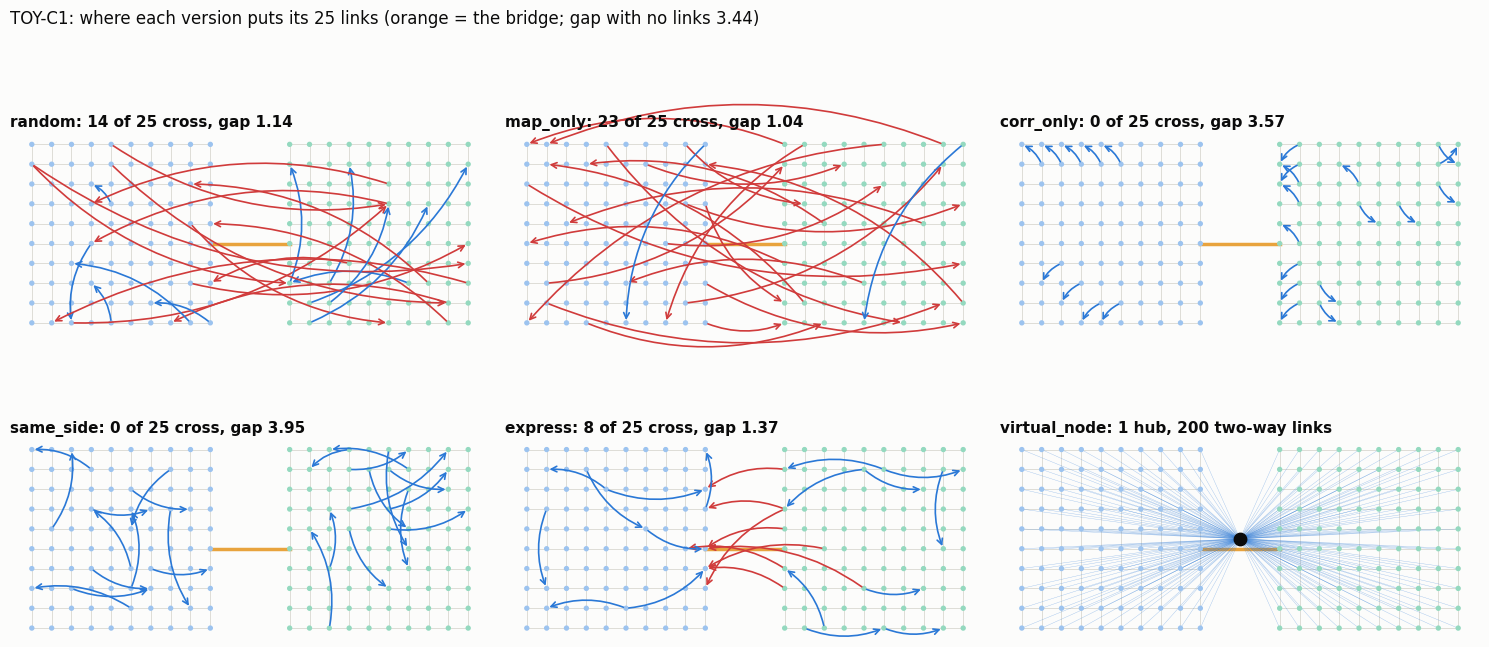

In [8]:
INK, MUTED = '#0b0b0b', '#898781'
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'text.color': INK,
                     'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold'})
loc_path = os.path.join(RAW_DIR, 'toy', 'TOY-C1_locations.csv')
if 'TOY-C1' in BUILT and os.path.exists(loc_path):
    b = BUILT['TOY-C1']
    loc = pd.read_csv(loc_path, dtype={'sensor_id': str}).set_index('sensor_id').loc[b['ids']]
    xy = loc[['x', 'y']].to_numpy(float)
    fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
    srow = summary[summary.dataset == 'TOY-C1'].set_index('version')
    for ax, v in zip(axes.ravel(), VERSIONS):
        i, j = np.where(np.triu(b['W'] > 0, 1))
        for a_, c_ in zip(i, j):
            cross = b['district'][a_] != b['district'][c_]
            ax.plot(xy[[a_, c_], 0], xy[[a_, c_], 1], color='#e8a33d' if cross else '#d9d8d0',
                    lw=2.5 if cross else 0.6, zorder=1)
        ax.scatter(xy[:, 0], xy[:, 1], s=8, color=['#9cc3ef' if d == 'A' else '#94d9bf' for d in b['district']], zorder=2)
        if v == 'virtual_node':
            hub = xy.mean(0)
            for p in xy:
                ax.plot([hub[0], p[0]], [hub[1], p[1]], color='#2a78d6', lw=0.25, alpha=0.5, zorder=1)
            ax.scatter(*hub, s=80, color=INK, zorder=3)
            title = 'virtual_node: 1 hub, 200 two-way links'
        else:
            L = b['links'][v][:K_MAIN]
            for u, w in L:
                c = '#d03b3b' if b['district'][u] != b['district'][w] else '#2a78d6'
                ax.annotate('', xy=xy[w], xytext=xy[u], zorder=3,
                            arrowprops=dict(arrowstyle='->', color=c, lw=1.2, shrinkA=2, shrinkB=2,
                                            connectionstyle='arc3,rad=0.2'))
            s = srow.loc[v]
            title = f'{v}: {int(s.crossing)} of {len(L)} cross, gap {s.gap:.2f}'
        ax.set_title(title, loc='left'); ax.set_aspect('equal'); ax.axis('off')
    fig.suptitle(f'TOY-C1: where each version puts its {K_MAIN} links (orange = the bridge; '
                 f'gap with no links {srow.loc["original"].gap:.2f})', x=0.01, ha='left', fontsize=12)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, 'graph_versions_TOY-C1.png'), dpi=200, bbox_inches='tight')
    plt.show()
else:
    print('TOY-C1 or its locations file not found: no figure')

## Done

* `data/graphs/<dataset>/{random, map_only, corr_only, same_side}_K{5,10,25,50}.pkl` with their link lists, `virtual_node_K25.pkl`, and step 7's `express_K*.pkl` checked to match. Step 12's status board turns these runs from `blocked` to `not_started`.
* `data/graphs/<dataset>/versions_summary.csv`: the structure table for the report.
* `figures/graph_versions_TOY-C1.png`: the six versions on the toy city.

Rerun this notebook if step 6-7 is rerun (for example after changing `RHO_MIN`): every version is rebuilt from the same ρ, so they stay comparable.